# Predictive Modeling for Employee Salary, Resignation and Promotion
##### Group: Beyza Değirmenci 201101077, Elifnur Çiftçi 191101074
##### Course: BIL470

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier

# One-Time Data Preparation Script
This code merges our sql tables into one snapshot parquet meaningfully.
It has been run once and saved as 'employee_snapshot_data.parquet'.
It is now commented out to prevent it from running again.

# 1. Load Clean Data
Loading the 'employee_snapshot_data.parquet' file

In [ ]:
df = pd.read_parquet('employee_snapshot_data.parquet')
print("Clean and up-to-date employee snapshot loaded.")

Clean and up-to-date employee snapshot loaded.


# 2. Feature Engineering & Target Creation
The dataset's last known date. We use this to calculate tenure for active employees.

In [ ]:
today = pd.to_datetime('2002-08-01')

### -- Target 1: Resignation --
If 'dept_emp_to_date' is NOT Null (NaT), the employee has resigned (1).
If it is Null (NaT), they are still active (0).

In [ ]:
df['has_resigned'] = df['dept_emp_to_date'].notnull().astype(int) # 1 = Resigned, 0 = Active

### -- Target 2: Promotion (Is Manager) --
If 'managed_dept_no' is NOT Null (NaN), that person is a manager.

In [ ]:
df['is_manager'] = df['managed_dept_no'].notnull().astype(int) # 1 = Manager, 0 = Not Manager

### -- Target 3: Salary --
The 'current_salary' column is already our target.

#### -- New Features: Age and Tenure --
For tenure calculation, use 'dept_emp_to_date' for resigned employees
and 'today' (2002-08-01) for active employees.

In [ ]:
tenure_end_date = df['dept_emp_to_date'].fillna(today)

df['tenure'] = (tenure_end_date - df['hire_date']).dt.days / 365.25
df['age'] = (tenure_end_date - df['birth_date']).dt.days / 365.25

# Clean up any negative tenure/age values (if data is noisy)
df['tenure'] = df['tenure'].clip(lower=0)
df['age'] = df['age'].clip(lower=0)

print("Target variables (has_resigned, is_manager) and features (tenure, age) created.")

Target variables (has_resigned, is_manager) and features (tenure, age) created.


### Data Dictionary: `employee_snapshot_data.parquet`


#### Employee Information
- **emp_no**: Unique Employee ID  
- **birth_date**: Date of birth  
- **first_name**: First name  
- **last_name**: Last name  
- **gender**: Employee's gender (`M` / `F`)  
- **hire_date**: Date the employee was hired  

---

#### Current Job Status
- **current_salary**: The employee's most recent salary  
- **salary_to_date**: The end date of the current salary record  
- **current_title**: The employee's most recent job title  
- **title_to_date**: The end date of the current title record  
- **dept_no**: Department ID  
- **dept_name**: Department name  
- **dept_emp_to_date**: The end date of the employee's department tenure.  
  - *Null (or NaT) indicates the employee is still active.*

---

#### Manager Information
- **managed_dept_no**: Department ID managed by this employee (if they are a manager)  
- **manager_to_date**: The end date of their management tenure  

---

#### Engineered Features & Targets (Created for Modeling)
- **has_resigned (Target)**:  
  `1` if the employee has resigned (`dept_emp_to_date` is not null),  
  `0` if they are active.  

- **is_manager (Target)**:  
  `1` if the employee is a manager (`managed_dept_no` is not null),  
  `0` otherwise.  

- **tenure (Feature)**:  
  Employee's tenure in years, calculated against **2002-08-01** for active employees.  

- **age (Feature)**:  
  Employee's age in years, calculated against their end date or **2002-08-01**.  


# 3. Exploratory Data Analysis (EDA)

### -- Target 1: Resignation Analysis --

/tmp/ipython-input-2545413003.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='has_resigned', palette=['green', 'red'])


Resignation Distribution (1=Resigned, 0=Active):
 has_resigned
0    0.800349
1    0.199651
Name: proportion, dtype: float64


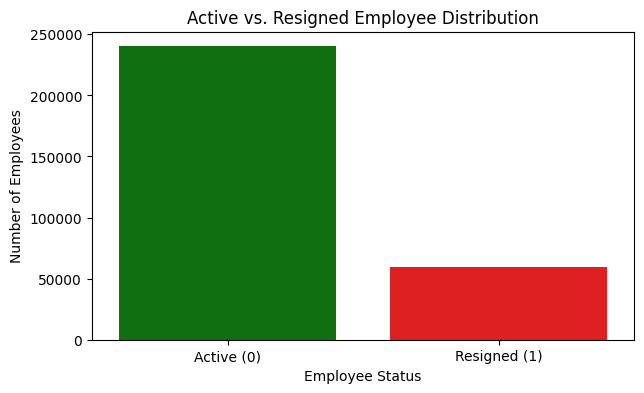

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='has_resigned', palette=['green', 'red'])
plt.title('Active vs. Resigned Employee Distribution')
plt.xticks([0, 1], ['Active (0)', 'Resigned (1)'])
plt.ylabel('Number of Employees')
plt.xlabel('Employee Status')
plt.savefig('resignation_distribution.png')
print("Resignation Distribution (1=Resigned, 0=Active):\n", df['has_resigned'].value_counts(normalize=True))

### -- Target 2: Promotion (Manager) Analysis --

/tmp/ipython-input-1947062896.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='is_manager', palette=['blue', 'orange'])


Manager (Promotion) Distribution:
 is_manager
0    0.99992
1    0.00008
Name: proportion, dtype: float64


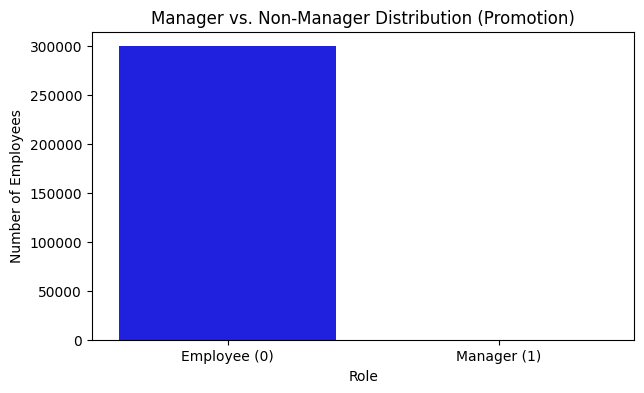

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='is_manager', palette=['blue', 'orange'])
plt.title('Manager vs. Non-Manager Distribution (Promotion)')
plt.xticks([0, 1], ['Employee (0)', 'Manager (1)'])
plt.ylabel('Number of Employees')
plt.xlabel('Role')
plt.savefig('manager_distribution.png')
print("Manager (Promotion) Distribution:\n", df['is_manager'].value_counts(normalize=True))

### -- Target 3: Salary Analysis --

Average Salary: 69928.29


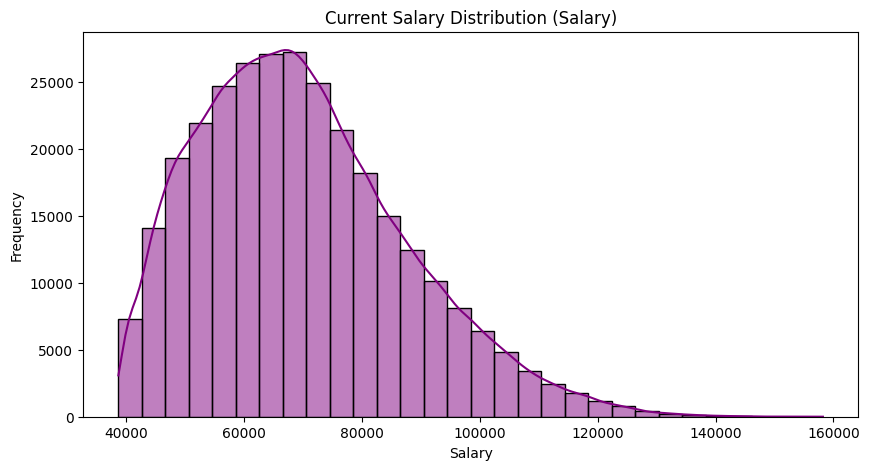

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(df['current_salary'].dropna(), kde=True, bins=30, color='purple')
plt.title('Current Salary Distribution (Salary)')
plt.xlabel('Salary')
plt.ylabel('Frequency')
plt.savefig('salary_distribution.png')
print(f"Average Salary: {df['current_salary'].mean():.2f}")

## -- Correlations --
### Correlation Matrix

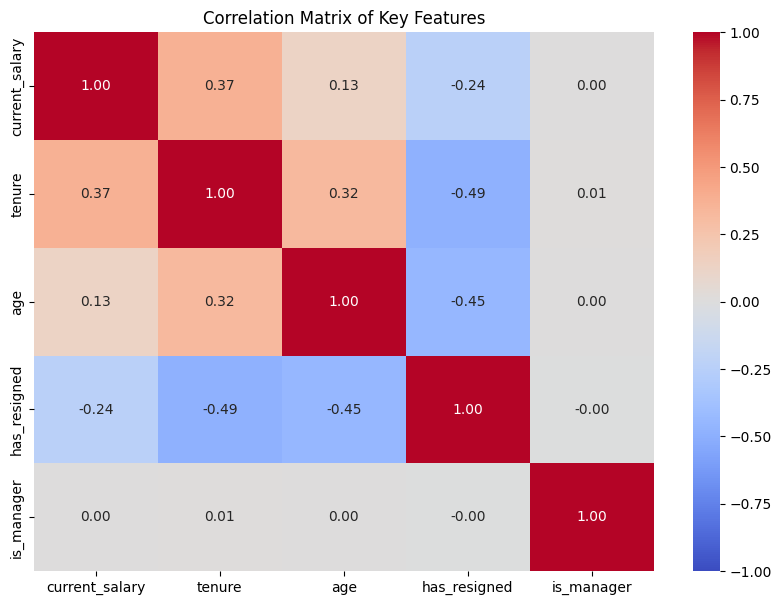

In [ ]:
numeric_features_df = df[['current_salary', 'tenure', 'age', 'has_resigned', 'is_manager']]

corr_matrix = numeric_features_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            vmin=-1, vmax=1)

plt.title('Correlation Matrix of Key Features')
plt.savefig('correlation_matrix.png')
plt.show()

### Salary vs. Tenure

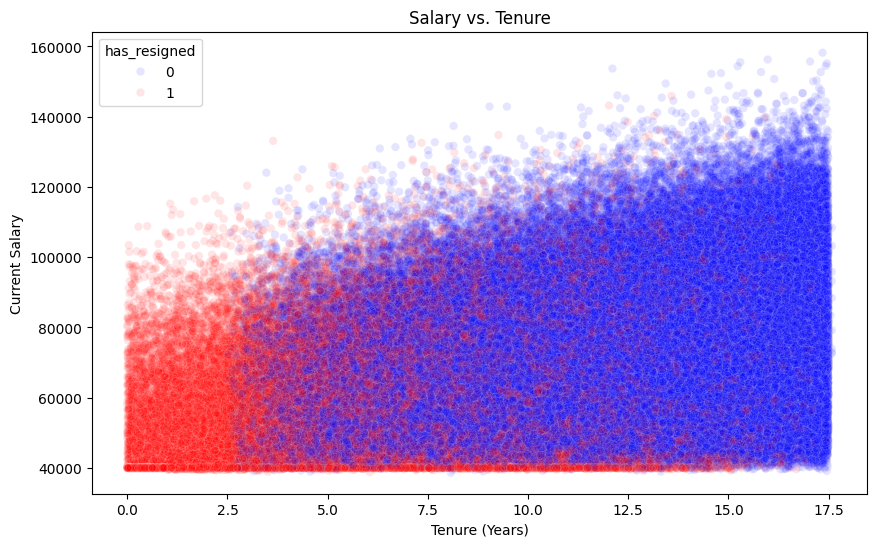

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='tenure', y='current_salary', hue='has_resigned', alpha=0.1, palette=['blue', 'red'])
plt.title('Salary vs. Tenure')
plt.xlabel('Tenure (Years)')
plt.ylabel('Current Salary')
plt.savefig('salary_vs_tenure.png')

### Salary by Department

/tmp/ipython-input-3784808428.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='dept_name', y='current_salary', palette='viridis')


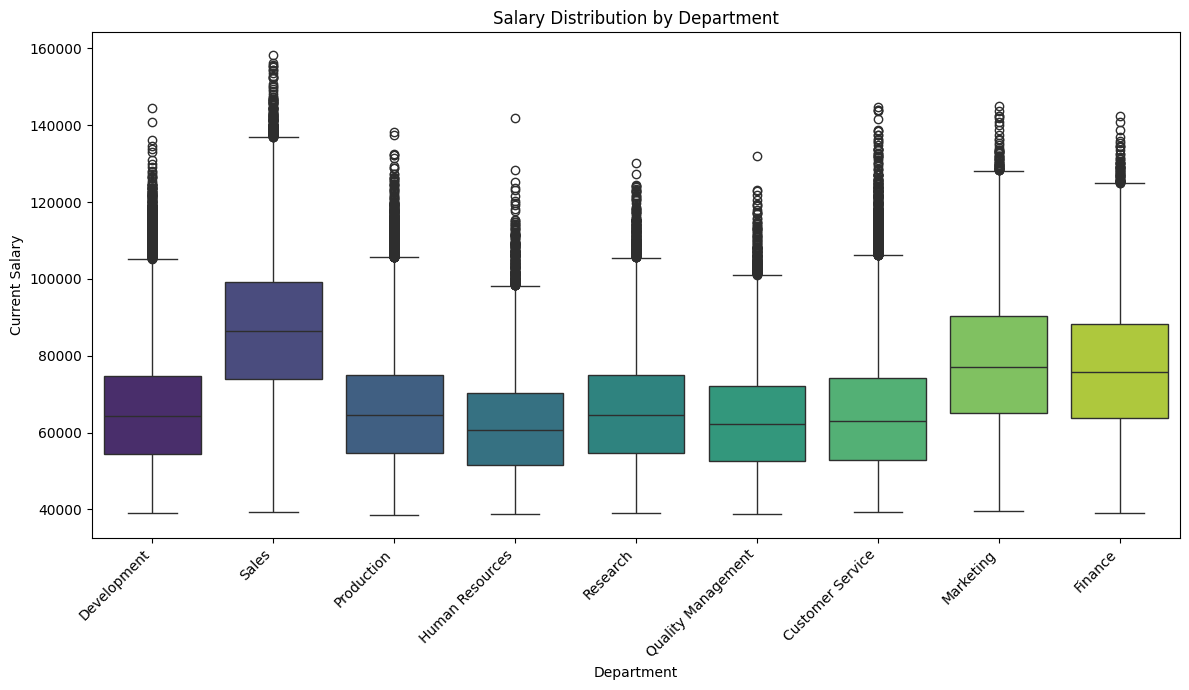

In [ ]:
plt.figure(figsize=(12, 7))
sns.boxplot(data=df, x='dept_name', y='current_salary', palette='viridis')
plt.title('Salary Distribution by Department')
plt.xlabel('Department')
plt.ylabel('Current Salary')
plt.xticks(rotation=45, ha='right') # Rotate labels for readability
plt.tight_layout() # Adjust plot to prevent label overlap
plt.savefig('salary_by_department.png')

### Resignation Rate by Department

/tmp/ipython-input-655222935.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dept_resignation_rate, x='has_resigned', y='dept_name', palette='coolwarm')


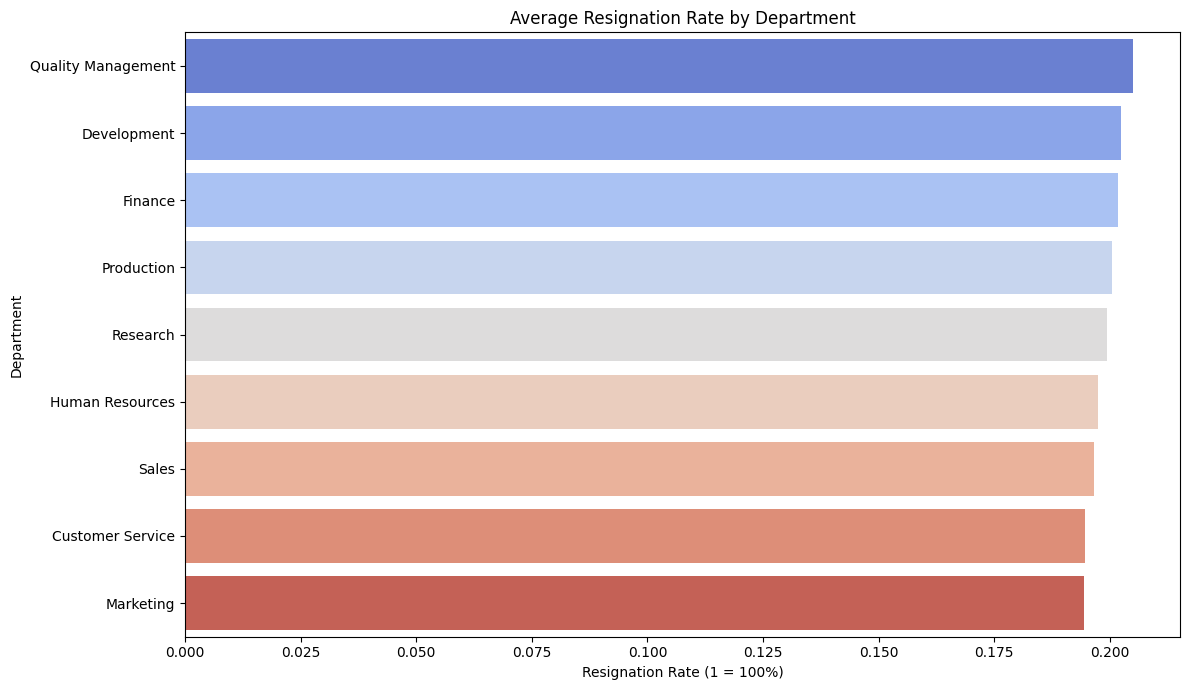

In [ ]:
dept_resignation_rate = df.groupby('dept_name')['has_resigned'].mean().reset_index().sort_values(by='has_resigned', ascending=False)
plt.figure(figsize=(12, 7))
sns.barplot(data=dept_resignation_rate, x='has_resigned', y='dept_name', palette='coolwarm')
plt.title('Average Resignation Rate by Department')
plt.xlabel('Resignation Rate (1 = 100%)')
plt.ylabel('Department')
plt.tight_layout()
plt.savefig('resignation_by_department.png')

# Salary Prediction

## Feature Preparation

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

X = df[['age', 'tenure', 'gender', 'dept_name', 'current_title', 'is_manager']]
y = df['current_salary']

categorical_features = ['gender', 'dept_name', 'current_title']
numeric_features = ['age', 'tenure', 'is_manager']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape


((240019, 6), (60005, 6))

## Linear Regression Model

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

print("Linear Regression Results:")
print("MAE:", mean_absolute_error(y_test, lr_preds))

mse = mean_squared_error(y_test, lr_preds)
rmse = mse ** 0.5
print("RMSE:", rmse)

print("R²:", r2_score(y_test, lr_preds))


Linear Regression Results:
MAE: 10728.584022045938
RMSE: 13672.780889586427
R²: 0.39942183008743004


## Random Forest Regressor

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rf_fast = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=80,
        max_depth=15,
        min_samples_split=10,
        n_jobs=-1,
        random_state=42
    ))
])

rf_fast.fit(X_train, y_train)
rf_preds = rf_fast.predict(X_test)

rf_mse = mean_squared_error(y_test, rf_preds)
rf_rmse = rf_mse ** 0.5

print("Fast Random Forest Results:")
print("MAE:", mean_absolute_error(y_test, rf_preds))
print("RMSE:", rf_rmse)
print("R²:", r2_score(y_test, rf_preds))


Fast Random Forest Results:
MAE: 10605.149588908795
RMSE: 13536.030927018553
R²: 0.4113752624092708


## LightGBM Regressor

In [ ]:
from lightgbm import LGBMRegressor

lgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LGBMRegressor(random_state=42))
])

lgb_model.fit(X_train, y_train)
lgb_preds = lgb_model.predict(X_test)

print("LightGBM Results:")
print("MAE:", mean_absolute_error(y_test, lgb_preds))

mse = mean_squared_error(y_test, lgb_preds)
rmse = mse ** 0.5
print("RMSE:", rmse)

print("R²:", r2_score(y_test, lgb_preds))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004147 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 544
[LightGBM] [Info] Number of data points in the train set: 240019, number of used features: 19
[LightGBM] [Info] Start training from score 69923.206704


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM Results:
MAE: 10558.825792265847
RMSE: 13465.253417268392
R²: 0.4175147981864794


## Random Forest Feature Importance

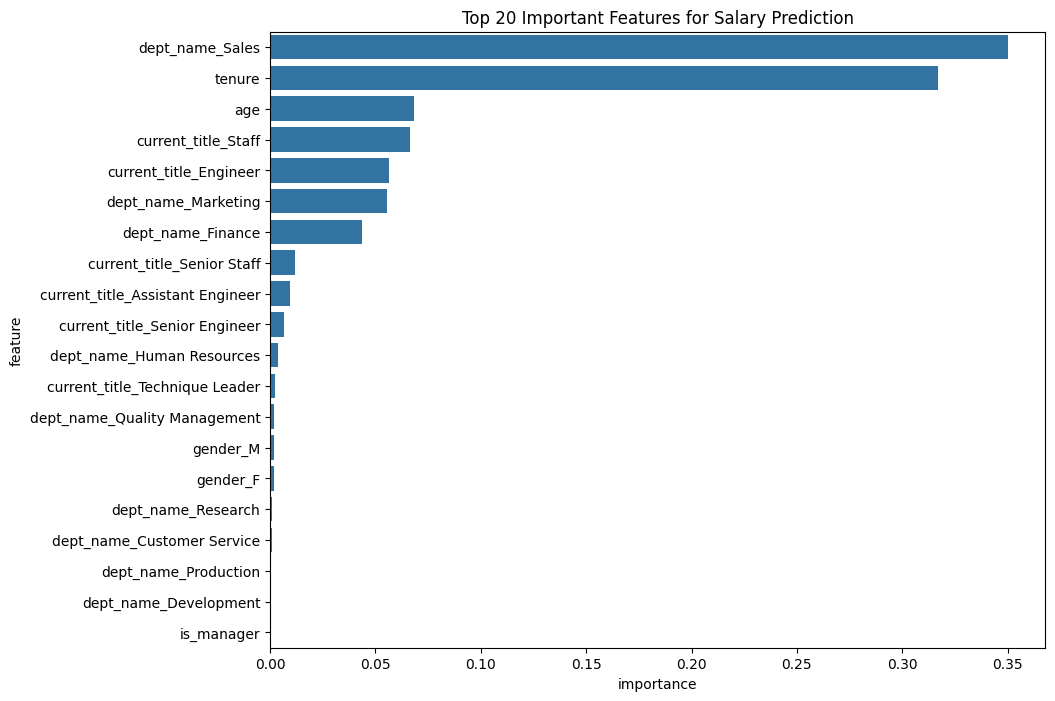

In [ ]:
# Get feature names from the preprocessor
ohe = preprocessor.named_transformers_['cat']
ohe_features = ohe.get_feature_names_out(categorical_features)

# Combine categorical + numeric feature names
final_feature_names = list(ohe_features) + numeric_features

# Extract importance values from the forest
importances = rf_fast.named_steps['model'].feature_importances_

# Build dataframe
importance_df = pd.DataFrame({
    'feature': final_feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

# Show top 20
plt.figure(figsize=(10,8))
sns.barplot(
    data=importance_df.head(20),
    x='importance',
    y='feature'
)
plt.title("Top 20 Important Features for Salary Prediction")
plt.show()


## Salary Prediction – Model Comparison Script

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

def evaluate_regression_model(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [ ]:
results = []

results.append(
    evaluate_regression_model(
        "Linear Regression",
        y_test,
        lr_preds
    )
)

results.append(
    evaluate_regression_model(
        "Fast Random Forest",
        y_test,
        rf_preds
    )
)

results.append(
    evaluate_regression_model(
        "LightGBM",
        y_test,
        lgb_preds
    )
)

results_df = pd.DataFrame(results)
results_df.sort_values(by="RMSE")


,Model,MAE,RMSE,R2
2,LightGBM,10558.825792,13465.253417,0.417515
1,Fast Random Forest,10605.149589,13536.030927,0.411375
0,Linear Regression,10728.584022,13672.780890,0.399422


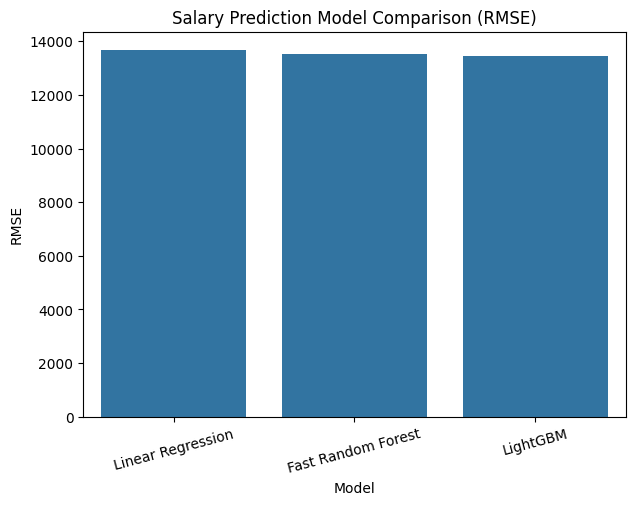

In [ ]:
plt.figure(figsize=(7,5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("Salary Prediction Model Comparison (RMSE)")
plt.xticks(rotation=15)
plt.show()


## Cross-Validation – Linear Regression

In [ ]:
from sklearn.model_selection import cross_val_score

lr_cv = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

lr_cv_scores = cross_val_score(
    lr_cv,
    X,
    y,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

print("Linear Regression CV RMSE:")
print("Mean:", -lr_cv_scores.mean())
print("Std:", lr_cv_scores.std())


Linear Regression CV RMSE:
Mean: 13701.99951377741
Std: 23.27094353149149


## Cross-Validation – Fast Random Forest

In [ ]:
rf_cv = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=40,
        max_depth=12,
        min_samples_split=20,
        n_jobs=-1,
        random_state=42
    ))
])

rf_cv_scores = cross_val_score(
    rf_cv,
    X,
    y,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=1
)

print("Fast Random Forest CV RMSE:")
print("Mean:", -rf_cv_scores.mean())
print("Std:", rf_cv_scores.std())


Fast Random Forest CV RMSE:
Mean: 13528.599083736755
Std: 20.804847118422416


## Cross-Validation – LightGBM

In [ ]:
lgb_cv = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LGBMRegressor(random_state=42))
])

lgb_cv_scores = cross_val_score(
    lgb_cv,
    X,
    y,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

print("LightGBM CV RMSE:")
print("Mean:", -lgb_cv_scores.mean())
print("Std:", lgb_cv_scores.std())


LightGBM CV RMSE:
Mean: 13492.512796200963
Std: 23.40339756468351


#Attrition Prediction

In [ ]:
# 1. Convert Categorical Data to Numeric (One-Hot Encoding)
# We convert categorical columns like 'gender', 'dept_name', and 'title' into binary columns.
df_model = pd.get_dummies(df, columns=['gender', 'dept_name', 'current_title'], drop_first=True)

# 2. Drop Unnecessary or "Data Leakage" Columns
# Dates, IDs, and columns that directly reveal the target variable (like 'dept_emp_to_date') must be removed.
# We also remove 'dept_no' here as it is a string identifier and redundant after encoding dept_name.
drop_cols = [
    'emp_no', 'birth_date', 'hire_date', 'salary_to_date', 'title_to_date',
    'dept_emp_to_date', 'managed_dept_no', 'manager_to_date',
    'first_name', 'last_name', 'dept_no'
]

# Drop the columns (errors='ignore' ensures the code runs even if a column is already missing)
df_model = df_model.drop(columns=drop_cols, errors='ignore')

# 3. Handle Missing Values
# Drop rows with missing values (assuming the number of missing rows is negligible)
df_model = df_model.dropna()

# 4. Final Data Type Verification
# To ensure model compatibility, we select only numeric (numbers) and boolean (True/False) types.
df_model = df_model.select_dtypes(include=['number', 'bool'])

print("Final Processed Dataset Shape:", df_model.shape)
df_model.head()

Final Processed Dataset Shape: (300024, 20)


,current_salary,has_resigned,is_manager,tenure,age,gender_M,dept_name_Development,dept_name_Finance,dept_name_Human Resources,dept_name_Marketing,dept_name_Production,dept_name_Quality Management,dept_name_Research,dept_name_Sales,current_title_Engineer,current_title_Manager,current_title_Senior Engineer,current_title_Senior Staff,current_title_Staff,current_title_Technique Leader
0,88958,0,0,16.098563,48.911704,True,True,False,False,False,False,False,False,False,False,False,True,False,False,False
1,72527,0,0,16.692676,38.162902,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False
2,43311,0,0,15.926078,42.661191,True,False,False,False,False,True,False,False,False,False,False,True,False,False,False
3,74057,0,0,15.665982,48.251882,True,False,False,False,False,True,False,False,False,False,False,True,False,False,False
4,94692,0,0,12.884326,47.526352,True,False,False,True,False,False,False,False,False,False,False,False,True,False,False


Training Logistic Regression...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



>> Logistic Regression Accuracy: 0.8724
              precision    recall  f1-score   support

           0       0.89      0.97      0.92     48025
           1       0.78      0.50      0.61     11980

    accuracy                           0.87     60005
   macro avg       0.83      0.73      0.77     60005
weighted avg       0.86      0.87      0.86     60005

Training Random Forest...

>> Random Forest Accuracy: 0.8890
              precision    recall  f1-score   support

           0       0.89      0.98      0.93     48025
           1       0.86      0.53      0.66     11980

    accuracy                           0.89     60005
   macro avg       0.88      0.75      0.79     60005
weighted avg       0.89      0.89      0.88     60005



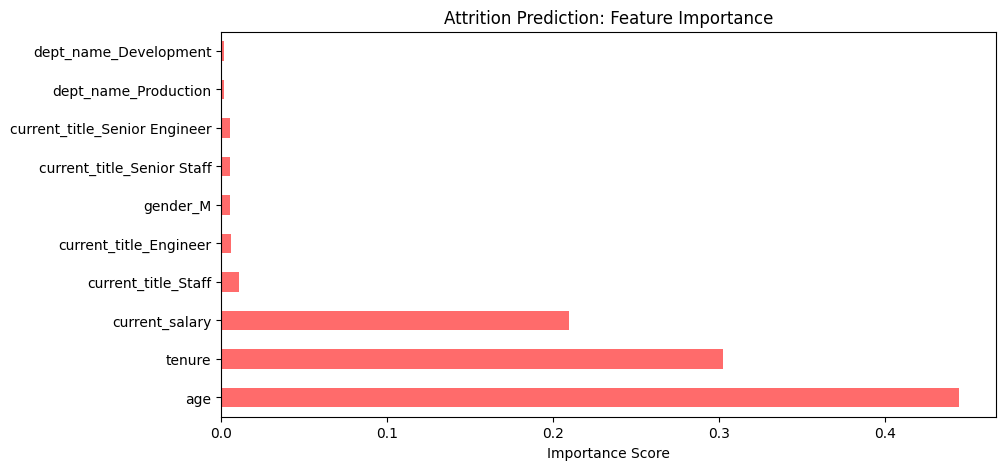

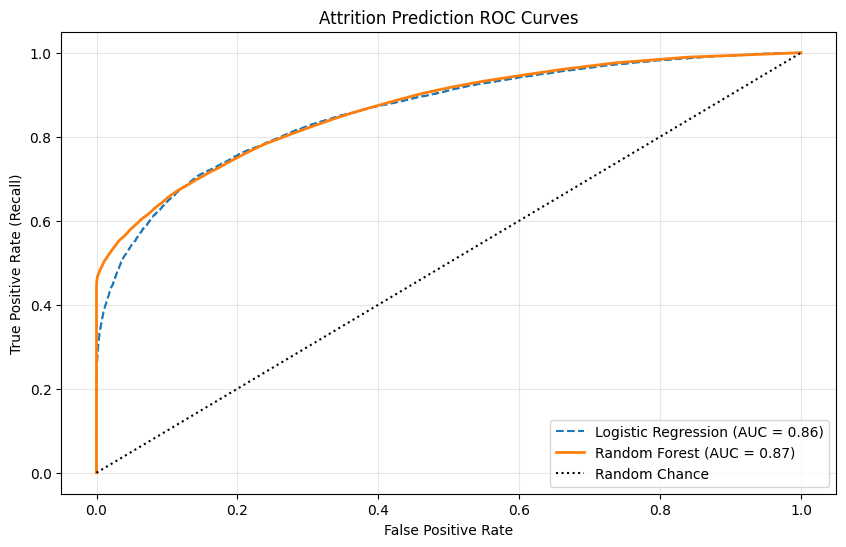

In [ ]:
# --- 1. Data Preparation ---
# Target: has_resigned
# Features to drop: has_resigned (target), is_manager (to prevent data leakage)
# Note: current_salary is used as an INPUT here, because salary affects attrition.
X_attrition = df_model.drop(['has_resigned', 'is_manager'], axis=1)
y_attrition = df_model['has_resigned']

# Train/Test Split
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_attrition, y_attrition, test_size=0.2, random_state=42, stratify=y_attrition
)

# --- 2. Model 1: Logistic Regression ---
print("Training Logistic Regression...")
log_reg = LogisticRegression(max_iter=2000) # Increased iteration count
log_reg.fit(X_train_a, y_train_a)
y_pred_log = log_reg.predict(X_test_a)

print(f"\n>> Logistic Regression Accuracy: {accuracy_score(y_test_a, y_pred_log):.4f}")
print(classification_report(y_test_a, y_pred_log))

# --- 3. Model 2: Random Forest Classifier ---
print("Training Random Forest...")
rf_attrition = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_attrition.fit(X_train_a, y_train_a)
y_pred_rf = rf_attrition.predict(X_test_a)

print(f"\n>> Random Forest Accuracy: {accuracy_score(y_test_a, y_pred_rf):.4f}")
print(classification_report(y_test_a, y_pred_rf))

# --- 4. Feature Importance ---
feat_importances = pd.Series(rf_attrition.feature_importances_, index=X_train_a.columns)
plt.figure(figsize=(10, 5))
feat_importances.nlargest(10).plot(kind='barh', color='#ff6b6b')
plt.title('Attrition Prediction: Feature Importance')
plt.xlabel('Importance Score')
plt.show()

from sklearn.metrics import roc_curve, roc_auc_score


# 1. Get Probability Predictions from Models
# The predict_proba() function returns the probability of the output being 1,
# instead of just 0 or 1.
# By using [:, 1], we isolate the probabilities for class "1" (Resignation).

y_probs_log = log_reg.predict_proba(X_test_a)[:, 1]
y_probs_rf = rf_attrition.predict_proba(X_test_a)[:, 1]

# If you also trained an XGBoost model (in previous steps), get its probabilities too:
# y_probs_xgb = xgb_attrition.predict_proba(X_test_a)[:, 1]

# 2. Calculate FPR (False Positive Rate) and TPR (True Positive Rate)
fpr_log, tpr_log, _ = roc_curve(y_test_a, y_probs_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test_a, y_probs_rf)

# If XGBoost exists:
# fpr_xgb, tpr_xgb, _ = roc_curve(y_test_a, y_probs_xgb)

# 3. Calculate AUC Scores
auc_log = roc_auc_score(y_test_a, y_probs_log)
auc_rf = roc_auc_score(y_test_a, y_probs_rf)

# If XGBoost exists:
# auc_xgb = roc_auc_score(y_test_a, y_probs_xgb)

# 4. Plotting the Graph
plt.figure(figsize=(10, 6))

# Logistic Regression Curve
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {auc_log:.2f})', linestyle='--')

# Random Forest Curve
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})', linewidth=2)

# If XGBoost exists (uncomment the start of this line):
# plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {auc_xgb:.2f})', color='orange')

# Random Prediction Line (Reference)
plt.plot([0, 1], [0, 1], 'k:', label='Random Chance')

# Graph Settings
plt.title('Attrition Prediction ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

##Attrition Prediction with XGBOOST

Calculated Imbalance Ratio (Scale Pos Weight): 4.01
Training XGBoost model...

>> XGBoost Accuracy: 0.8287


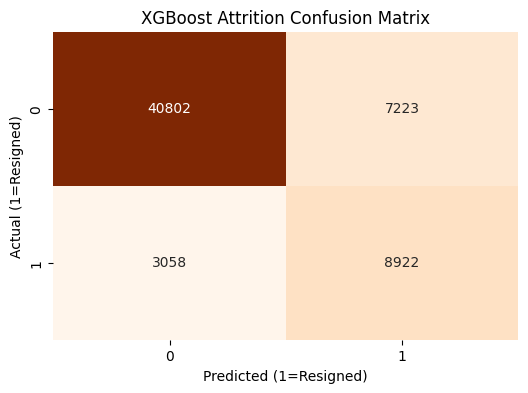


Classification Report (XGBoost):
              precision    recall  f1-score   support

           0       0.93      0.85      0.89     48025
           1       0.55      0.74      0.63     11980

    accuracy                           0.83     60005
   macro avg       0.74      0.80      0.76     60005
weighted avg       0.85      0.83      0.84     60005



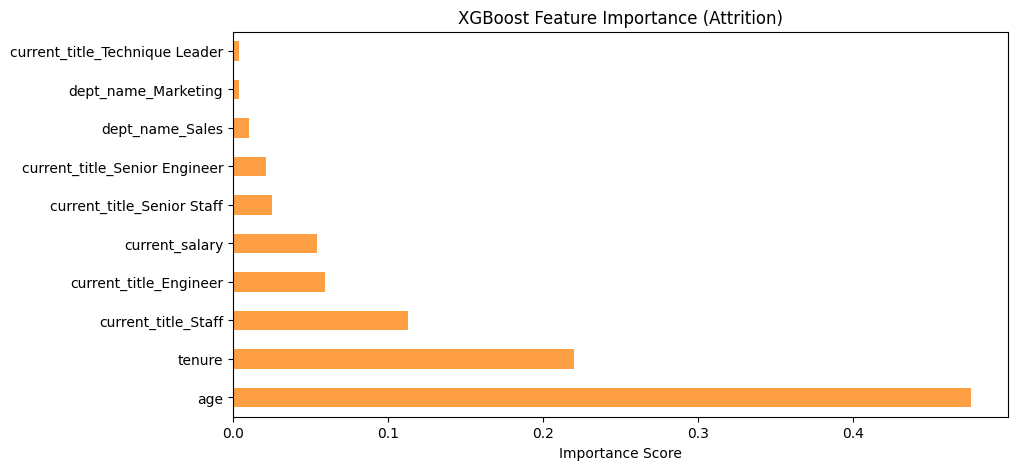


>> XGBoost AUC Score: 0.8889


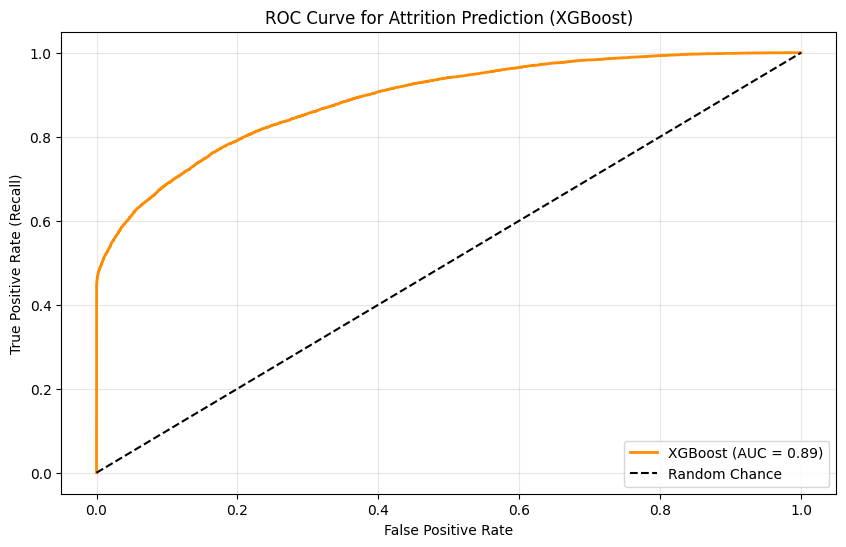

In [ ]:
# --- 1. Calculating Imbalance Ratio (for Scale Pos Weight) ---
# This ratio is critical for XGBoost to handle imbalanced data well.
# Ratio of Negative (0) / Positive (1) samples
ratio = float(np.sum(y_train_a == 0)) / np.sum(y_train_a == 1)
print(f"Calculated Imbalance Ratio (Scale Pos Weight): {ratio:.2f}")

# --- 2. Model: XGBoost Classifier ---
# scale_pos_weight: Increases the weight of the minority class (those who resigned).
xgb_attrition = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    scale_pos_weight=ratio,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

print("Training XGBoost model...")
xgb_attrition.fit(X_train_a, y_train_a)

# Prediction
y_pred_xgb = xgb_attrition.predict(X_test_a)

# --- 3. Evaluation ---
print(f"\n>> XGBoost Accuracy: {accuracy_score(y_test_a, y_pred_xgb):.4f}")

# Confusion Matrix
cm_xgb = confusion_matrix(y_test_a, y_pred_xgb)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges', cbar=False)
plt.title('XGBoost Attrition Confusion Matrix')
plt.xlabel('Predicted (1=Resigned)')
plt.ylabel('Actual (1=Resigned)')
plt.show()

print("\nClassification Report (XGBoost):")
# Compare the Recall value for class '1' here with the Random Forest result.
print(classification_report(y_test_a, y_pred_xgb))

# --- 4. Feature Importance ---
import pandas as pd
feat_importances_xgb = pd.Series(xgb_attrition.feature_importances_, index=X_train_a.columns)
plt.figure(figsize=(10, 5))
feat_importances_xgb.nlargest(10).plot(kind='barh', color='#ff9f43')
plt.title('XGBoost Feature Importance (Attrition)')
plt.xlabel('Importance Score')
plt.show()

# --- 5. ROC Curve and AUC Score ---
# Get predicted probabilities for the positive class (1 = Resigned)
y_probs_xgb = xgb_attrition.predict_proba(X_test_a)[:, 1]

# Calculate AUC Score
auc_score = roc_auc_score(y_test_a, y_probs_xgb)
print(f"\n>> XGBoost AUC Score: {auc_score:.4f}")

# Calculate ROC Curve points (False Positive Rate, True Positive Rate)
fpr, tpr, thresholds = roc_curve(y_test_a, y_probs_xgb)

# Plot ROC Curve
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {auc_score:.2f})', color='darkorange', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance') # Diagonal reference line
plt.title('ROC Curve for Attrition Prediction (XGBoost)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

##Attrition Prediciton Model Comparison


--- Model Performance & Overfitting Analysis ---
                     Train Accuracy  Test Accuracy  Diff (Overfitting Risk)  \
Model                                                                         
XGBoost                    0.827768       0.828664                -0.000896   
Random Forest              0.999938       0.889043                 0.110895   
Logistic Regression        0.872018       0.872411                -0.000392   

                     Recall (Sensitivity)  AUC Score  
Model                                                 
XGBoost                          0.744741   0.888915  
Random Forest                    0.528130   0.866631  
Logistic Regression              0.499583   0.860085  

[NOTE]: If 'Diff (Overfitting Risk)' is > 0.05 - 0.10, the model might be overfitting.
It is normal for Random Forest to have higher Train accuracy (e.g., 99%) vs Test (e.g., 88%).
The primary goal is to maximize Test Accuracy and Recall.


/tmp/ipython-input-2998891272.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_results.index, y=df_results["Recall (Sensitivity)"], palette="magma")


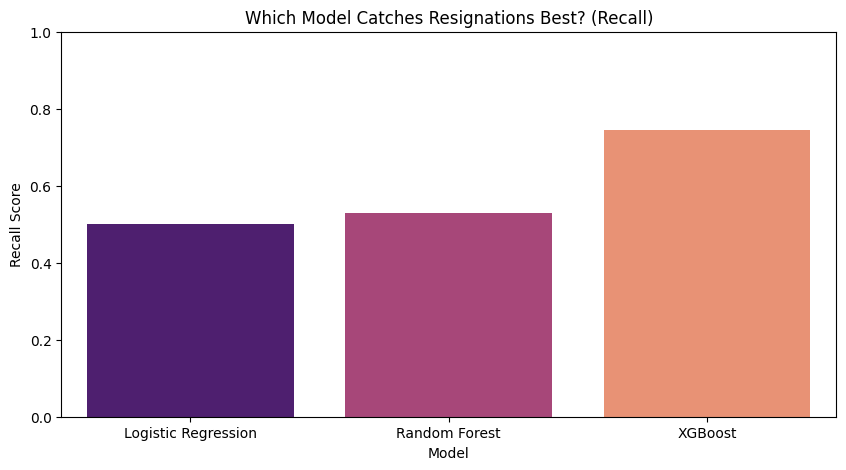

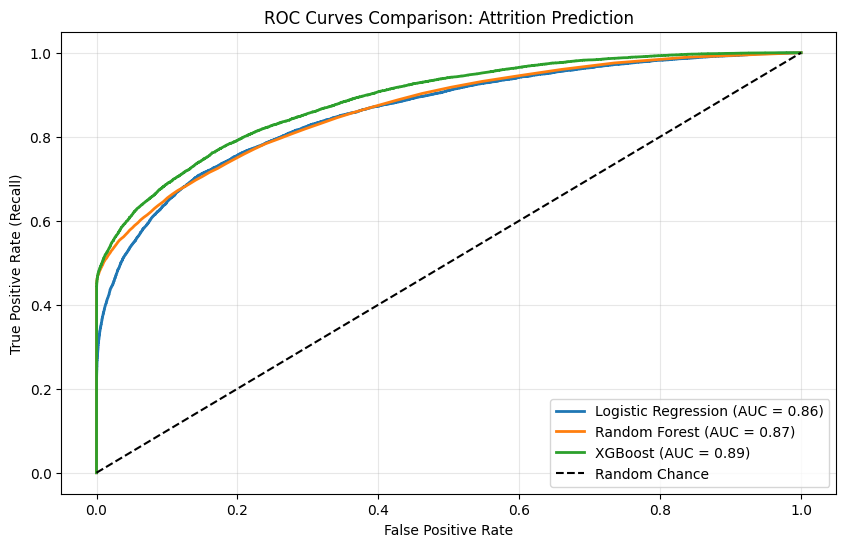

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_auc_score, roc_curve

# Dictionary containing the trained model objects
# Ensure log_reg, rf_attrition, and xgb_attrition are already trained.
models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf_attrition,
    "XGBoost": xgb_attrition
}

results_data = []
roc_data = {}

for name, model in models.items():
    # --- 1. PREDICTIONS (For both Train and Test Sets) ---
    y_pred_test = model.predict(X_test_a)
    y_pred_train = model.predict(X_train_a)  # Crucial for checking overfitting!

    # Get probabilities for Class 1 (Resigned) - Needed for AUC
    y_prob_test = model.predict_proba(X_test_a)[:, 1]

    # --- 2. METRICS (Test Set - The primary metrics for evaluation) ---
    test_acc = accuracy_score(y_test_a, y_pred_test)
    f1 = f1_score(y_test_a, y_pred_test, pos_label=1)
    recall = recall_score(y_test_a, y_pred_test, pos_label=1)
    precision = precision_score(y_test_a, y_pred_test, pos_label=1)
    auc = roc_auc_score(y_test_a, y_prob_test)

    # --- 3. OVERFITTING CHECK (Calculate Train Score) ---
    train_acc = accuracy_score(y_train_a, y_pred_train)

    # Calculate the Difference (Train - Test)
    # A large positive difference indicates overfitting.
    diff = train_acc - test_acc

    # Store metrics
    results_data.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Diff (Overfitting Risk)": diff,
        "Recall (Sensitivity)": recall,
        "F1-Score": f1,
        "AUC Score": auc
    })

    # Store ROC Curve data for plotting
    fpr, tpr, _ = roc_curve(y_test_a, y_prob_test)
    roc_data[name] = (fpr, tpr, auc)

# --- RESULTS TABLE ---
df_results = pd.DataFrame(results_data)
df_results.set_index("Model", inplace=True)

print("\n--- Model Performance & Overfitting Analysis ---")
# Reorder columns to highlight the overfitting check
cols = ["Train Accuracy", "Test Accuracy", "Diff (Overfitting Risk)", "Recall (Sensitivity)", "AUC Score"]
print(df_results[cols].sort_values(by="Recall (Sensitivity)", ascending=False))

# --- INTERPRETATION NOTE ---
print("\n[NOTE]: If 'Diff (Overfitting Risk)' is > 0.05 - 0.10, the model might be overfitting.")
print("It is normal for Random Forest to have higher Train accuracy (e.g., 99%) vs Test (e.g., 88%).")
print("The primary goal is to maximize Test Accuracy and Recall.")

# --- Visualization 1: Recall Comparison ---
plt.figure(figsize=(10, 5))
sns.barplot(x=df_results.index, y=df_results["Recall (Sensitivity)"], palette="magma")
plt.title("Which Model Catches Resignations Best? (Recall)")
plt.ylim(0, 1)
plt.ylabel("Recall Score")
plt.show()

# --- Visualization 2: ROC Curves Comparison ---
plt.figure(figsize=(10, 6))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.2f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.title('ROC Curves Comparison: Attrition Prediction')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()


#Promotion Prediction


>> Model 1: Training Decision Tree...
>> Model 2: Training XGBoost...
   Imbalance Ratio (Scale Pos Weight): 12631.58

   PROMOTION MODEL COMPARISON & CHECK     

--- Promotion Prediction Performance ---
               Train Accuracy  Test Accuracy  Diff (Overfitting Risk)  \
Model                                                                   
XGBoost              0.999517        0.99935                 0.000167   
Decision Tree        0.963886        0.96362                 0.000266   

               Recall (Sensitivity)  AUC Score  
Model                                           
XGBoost                         0.6   0.898042  
Decision Tree                   0.8   0.885453  


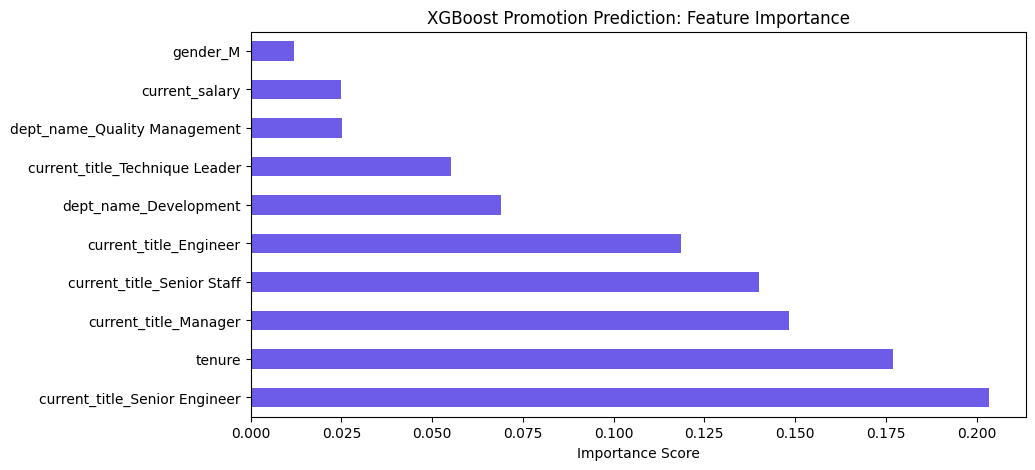

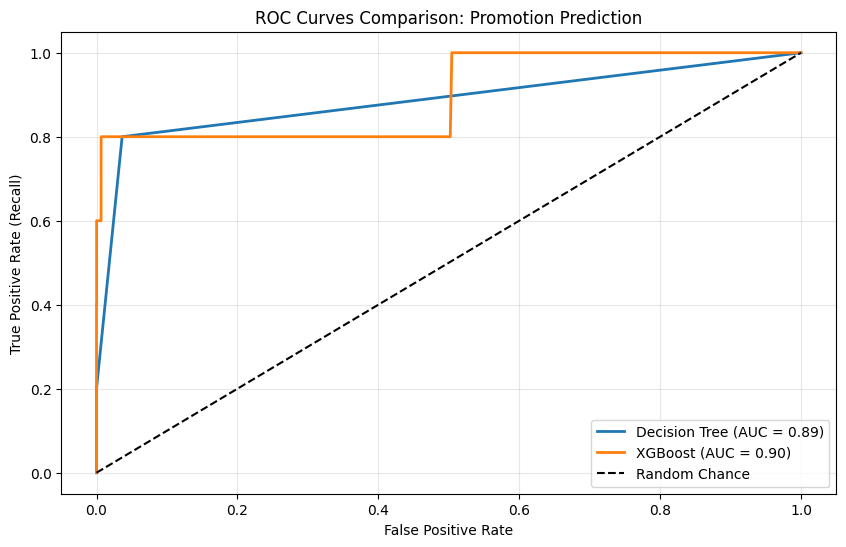

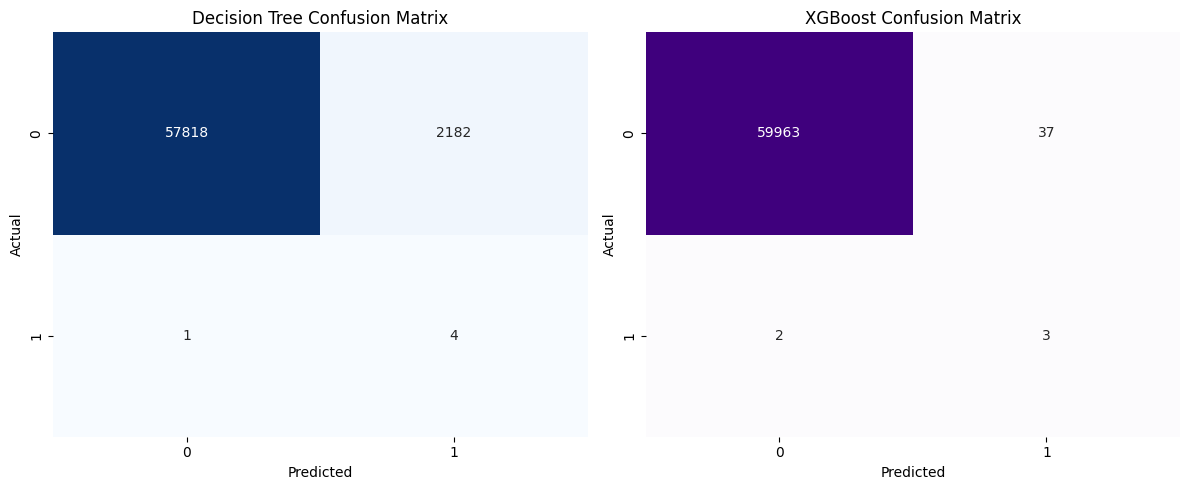

In [ ]:
# --- 1. Data Preparation ---
# Target: is_manager
# 'current_salary' and 'tenure' are kept as they are strong indicators for promotion.
X_promo = df_model.drop(['is_manager', 'has_resigned'], axis=1)
y_promo = df_model['is_manager']

# Train/Test Split
# Stratify is mandatory here because the 'Manager' class is extremely rare (0.008%).
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_promo, y_promo, test_size=0.2, random_state=42, stratify=y_promo
)

# ---------------------------------------------------------
# MODEL 1: DECISION TREE CLASSIFIER
# ---------------------------------------------------------
print("\n>> Model 1: Training Decision Tree...")
# class_weight='balanced': Automatically adjusts weights for the minority class.
dt_promo = DecisionTreeClassifier(random_state=42, class_weight='balanced', max_depth=5)
dt_promo.fit(X_train_p, y_train_p)

# ---------------------------------------------------------
# MODEL 2: XGBOOST CLASSIFIER
# ---------------------------------------------------------
print(">> Model 2: Training XGBoost...")

# Calculate Imbalance Ratio manually for XGBoost
ratio_promo = float(np.sum(y_train_p == 0)) / np.sum(y_train_p == 1)
print(f"   Imbalance Ratio (Scale Pos Weight): {ratio_promo:.2f}")

xgb_promo = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    scale_pos_weight=ratio_promo,  # Crucial for finding managers
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

xgb_promo.fit(X_train_p, y_train_p)

# =========================================================
#       MODEL COMPARISON & OVERFITTING CHECK
# =========================================================
print("\n==========================================")
print("   PROMOTION MODEL COMPARISON & CHECK     ")
print("==========================================")

models_promo = {
    "Decision Tree": dt_promo,
    "XGBoost": xgb_promo
}

results_data_p = []
roc_data_p = {}

for name, model in models_promo.items():
    # --- 1. PREDICTIONS (Train & Test) ---
    y_pred_test = model.predict(X_test_p)
    y_pred_train = model.predict(X_train_p) # Needed for overfitting check

    # Probabilities for Class 1 (Manager)
    y_prob_test = model.predict_proba(X_test_p)[:, 1]

    # --- 2. METRICS ---
    # Test Metrics
    test_acc = accuracy_score(y_test_p, y_pred_test)
    f1 = f1_score(y_test_p, y_pred_test, pos_label=1)
    recall = recall_score(y_test_p, y_pred_test, pos_label=1)
    precision = precision_score(y_test_p, y_pred_test, pos_label=1, zero_division=0)

    # Handle AUC calculation safely (in case of edge cases with small data)
    try:
        auc = roc_auc_score(y_test_p, y_prob_test)
        fpr, tpr, _ = roc_curve(y_test_p, y_prob_test)
        roc_data_p[name] = (fpr, tpr, auc)
    except ValueError:
        auc = 0.5
        print(f"Warning: AUC could not be calculated for {name} due to lack of positive samples in test.")

    # --- 3. OVERFITTING CHECK ---
    train_acc = accuracy_score(y_train_p, y_pred_train)
    diff = train_acc - test_acc

    results_data_p.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Diff (Overfitting Risk)": diff,
        "Recall (Sensitivity)": recall,
        "Precision": precision,
        "AUC Score": auc
    })

# --- Display Results Table ---
df_results_p = pd.DataFrame(results_data_p)
df_results_p.set_index("Model", inplace=True)

print("\n--- Promotion Prediction Performance ---")
# Sorting by AUC as it is more robust than Accuracy for this imbalance
cols = ["Train Accuracy", "Test Accuracy", "Diff (Overfitting Risk)", "Recall (Sensitivity)", "AUC Score"]
print(df_results_p[cols].sort_values(by="AUC Score", ascending=False))

# --- Visualization 1: Feature Importance (XGBoost) ---
feat_importances_p = pd.Series(xgb_promo.feature_importances_, index=X_train_p.columns)
plt.figure(figsize=(10, 5))
feat_importances_p.nlargest(10).plot(kind='barh', color='#6c5ce7')
plt.title('XGBoost Promotion Prediction: Feature Importance')
plt.xlabel('Importance Score')
plt.show()

# --- Visualization 2: ROC Curves Comparison ---
plt.figure(figsize=(10, 6))
for name, (fpr, tpr, auc) in roc_data_p.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.2f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.title('ROC Curves Comparison: Promotion Prediction')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

# --- Visualization 3: Confusion Matrix Comparison ---
# Comparing both models side-by-side to see how they handle the minority class
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Decision Tree CM
cm_dt = confusion_matrix(y_test_p, dt_promo.predict(X_test_p))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
ax[0].set_title('Decision Tree Confusion Matrix')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')

# XGBoost CM
cm_xgb = confusion_matrix(y_test_p, xgb_promo.predict(X_test_p))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Purples', cbar=False, ax=ax[1])
ax[1].set_title('XGBoost Confusion Matrix')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()